<a href="https://colab.research.google.com/github/njw257/bigdata/blob/main/week07_5685599_%EB%82%A8%EC%A2%85%EC%9A%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7주차 과제
빅데이터프로그래밍 · 통계학과

**이름:** 남종욱
**학번:** 5685599

## 과제 내용
은닉층 수와 활성화 함수를 변경하고 학습 결과를 비교합니다.

## 제출 방법
모든 셀을 실행해 출력과 그래프가 보이는 상태로 저장한 뒤 `week07_학번_이름.ipynb` 로 제출합니다.

**런타임 > 런타임 유형 변경 > T4 GPU** 를 먼저 선택하세요.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

transform = transforms.ToTensor()
train_set = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST("./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False)


device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 478kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.41MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.98MB/s]


## 공통 함수
아래 두 함수를 그대로 써서 모델만 바꿔 비교하세요.


In [2]:
def train_model(model, epochs=5, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(evaluate(model))
        print(f"  epoch {epoch+1}  test acc {hist[-1][1]:.4f}")
    return model, hist


def evaluate(model):
    model.eval()
    loss_fn = nn.CrossEntropyLoss()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * y.numel()
            correct += (out.argmax(dim=1) == y).sum().item()
            total += y.numel()
    return loss_sum / total, correct / total


## 문제 1. 은닉층 수 비교 (35점)
은닉층이 **1개 · 2개 · 3개**인 MLP를 각각 작성해 5 epoch 학습하고, 시험 정확도를 비교하세요.
은닉층 크기는 128로 통일합니다.


In [3]:
# 답안
# 은닉층 1개 모델
model1 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 10)
)

# 은닉층 2개 모델
model2 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 10)
)

# 은닉층 3개 모델
model3 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 10)
)

# 모델별 학습
models_depth = {
    "은닉층 1개": model1,
    "은닉층 2개": model2,
    "은닉층 3개": model3
}

hist_depth = {}

for name, model in models_depth.items():
    print(f"\n{name}")
    models_depth[name], hist_depth[name] = train_model(model, epochs=5)

# 모델별 최종 시험 정확도 출력
for name, hist in hist_depth.items():
    print(f"{name} 시험 정확도: {hist[-1][1]:.4f}")


은닉층 1개
  epoch 1  test acc 0.9341
  epoch 2  test acc 0.9529
  epoch 3  test acc 0.9629
  epoch 4  test acc 0.9706
  epoch 5  test acc 0.9710

은닉층 2개
  epoch 1  test acc 0.9389
  epoch 2  test acc 0.9590
  epoch 3  test acc 0.9689
  epoch 4  test acc 0.9693
  epoch 5  test acc 0.9710

은닉층 3개
  epoch 1  test acc 0.9475
  epoch 2  test acc 0.9630
  epoch 3  test acc 0.9624
  epoch 4  test acc 0.9721
  epoch 5  test acc 0.9754
은닉층 1개 시험 정확도: 0.9710
은닉층 2개 시험 정확도: 0.9710
은닉층 3개 시험 정확도: 0.9754


## 문제 2. 활성화 함수 비교 (35점)
은닉층 2개 모델에서 활성화 함수를 **ReLU · Sigmoid · Tanh** 로 바꿔 각각 학습하고 결과를 비교하세요.


In [4]:
# 답안
# 비교할 활성화 함수
activations = {
    "ReLU": nn.ReLU,
    "Sigmoid": nn.Sigmoid,
    "Tanh": nn.Tanh
}

models_act = {}
hist_act = {}

# 활성화 함수별 모델 생성 및 학습
for name, act in activations.items():
    model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128), act(),
        nn.Linear(128, 128), act(),
        nn.Linear(128, 10)
    )

    print(f"\n{name}")
    models_act[name], hist_act[name] = train_model(model, epochs=5)

# 활성화 함수별 최종 시험 정확도 출력
for name, hist in hist_act.items():
    print(f"{name} 시험 정확도: {hist[-1][1]:.4f}")


ReLU
  epoch 1  test acc 0.9435
  epoch 2  test acc 0.9632
  epoch 3  test acc 0.9668
  epoch 4  test acc 0.9731
  epoch 5  test acc 0.9742

Sigmoid
  epoch 1  test acc 0.9132
  epoch 2  test acc 0.9383
  epoch 3  test acc 0.9496
  epoch 4  test acc 0.9560
  epoch 5  test acc 0.9642

Tanh
  epoch 1  test acc 0.9432
  epoch 2  test acc 0.9604
  epoch 3  test acc 0.9689
  epoch 4  test acc 0.9691
  epoch 5  test acc 0.9731
ReLU 시험 정확도: 0.9742
Sigmoid 시험 정확도: 0.9642
Tanh 시험 정확도: 0.9731


## 문제 3. 결과 비교표와 그래프 (20점)
문제 1·2의 결과를 하나의 표로 정리하고, 학습 곡선을 한 그래프에 겹쳐 그리세요.

| 모델 | 은닉층 수 | 활성화 | 파라미터 수 | 시험 정확도 |


,모델,은닉층 수,활성화,파라미터 수,시험 정확도
0,은닉층 1개,1,ReLU,101770,0.9710
1,은닉층 2개,2,ReLU,118282,0.9710
2,은닉층 3개,3,ReLU,134794,0.9754
3,ReLU,2,ReLU,118282,0.9742
4,Sigmoid,2,Sigmoid,118282,0.9642
5,Tanh,2,Tanh,118282,0.9731


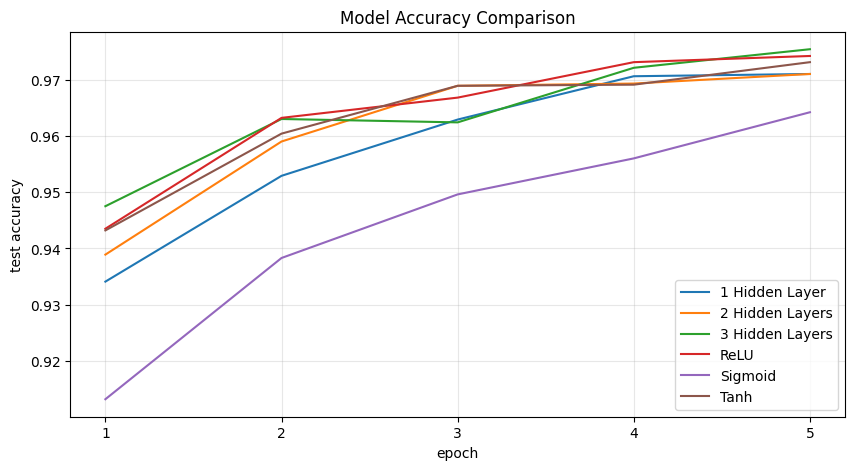

In [6]:
# 답안
# 문제 1, 2의 모델과 학습 결과 정리
results = [
    ("은닉층 1개", model1, hist_depth["은닉층 1개"], 1, "ReLU"),
    ("은닉층 2개", model2, hist_depth["은닉층 2개"], 2, "ReLU"),
    ("은닉층 3개", model3, hist_depth["은닉층 3개"], 3, "ReLU"),
    ("ReLU", models_act["ReLU"], hist_act["ReLU"], 2, "ReLU"),
    ("Sigmoid", models_act["Sigmoid"], hist_act["Sigmoid"], 2, "Sigmoid"),
    ("Tanh", models_act["Tanh"], hist_act["Tanh"], 2, "Tanh")
]

# 모델별 비교표 생성
rows = []

for name, model, hist, depth, act in results:
    rows.append({
        "모델": name,
        "은닉층 수": depth,
        "활성화": act,
        "파라미터 수": sum(p.numel() for p in model.parameters()),
        "시험 정확도": hist[-1][1]
    })

display(pd.DataFrame(rows))

# 그래프 범례 이름 설정
labels = {
    "은닉층 1개": "1 Hidden Layer",
    "은닉층 2개": "2 Hidden Layers",
    "은닉층 3개": "3 Hidden Layers"
}

# 모델별 epoch 정확도 비교 그래프
plt.figure(figsize=(10, 5))

for name, model, hist, depth, act in results:
    acc = [h[1] for h in hist]
    plt.plot(range(1, 6), acc, label=labels.get(name, name))

plt.xlabel("epoch")
plt.ylabel("test accuracy")
plt.title("Model Accuracy Comparison")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 문제 4. 해석 (10점)
아래 세 가지를 각각 두세 줄로 적으세요.

1. 은닉층을 늘렸을 때 정확도가 어떻게 변했는가 — 계속 좋아지는가
2. Sigmoid가 ReLU보다 느리게 학습되는 이유
3. 가장 좋았던 조합과 그 이유


**답:**

1. 은닉층 1개와 2개 모델의 정확도는 97.10%로 같았고, 3개 모델은 97.54%로 가장 높았다. 따라서 은닉층을 늘린다고 정확도가 항상 향상되는 것은 아니다.

2. Sigmoid는 입력값이 크거나 작아지면 기울기가 작아져 학습이 느려질 수 있다. 실제로 1 epoch에서 ReLU는 94.35%, Sigmoid는 91.32%의 정확도를 보여 ReLU가 더 빠르게 학습되었다.

3. 은닉층 3개와 ReLU를 사용한 모델이 97.54%로 가장 높은 시험 정확도를 기록했다. 이번 실험에서는 은닉층을 추가한 구조가 MNIST 숫자 분류에 더 좋은 결과를 보였다.


## 문제 5. 오류 사례 확인 (보너스)
가장 좋았던 모델로 틀리게 예측한 이미지 8장을 그리고, 어떤 숫자를 어떤 숫자로 착각했는지 적으세요.


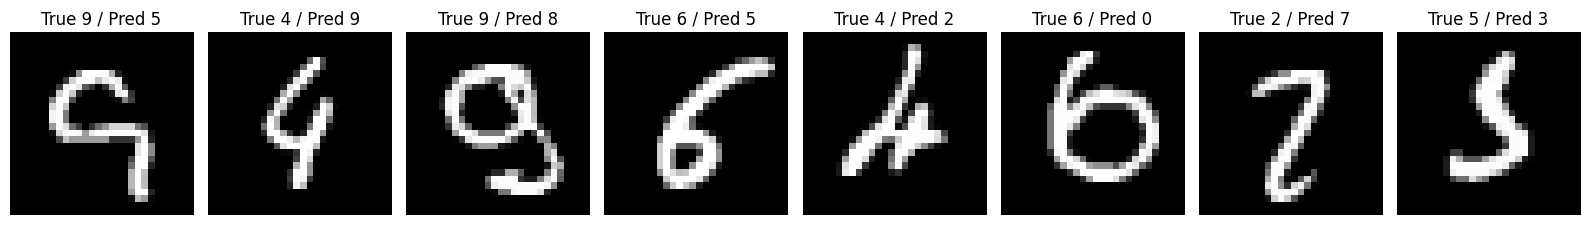

정답 9 → 예측 5
정답 4 → 예측 9
정답 9 → 예측 8
정답 6 → 예측 5
정답 4 → 예측 2
정답 6 → 예측 0
정답 2 → 예측 7
정답 5 → 예측 3


In [7]:
# 답안
# 가장 정확도가 높았던 은닉층 3개 모델 선택
model3.eval()

# 시험 데이터의 예측값과 정답 수집
all_pred, all_true, all_img = [], [], []

with torch.no_grad():
    for x, y in test_loader:
        out = model3(x.to(device))
        all_pred.append(out.argmax(dim=1).cpu())
        all_true.append(y)
        all_img.append(x)

pred = torch.cat(all_pred)
true = torch.cat(all_true)
imgs = torch.cat(all_img)

# 잘못 예측한 이미지 8개 선택
wrong_idx = (pred != true).nonzero().flatten()[:8]

# 잘못 예측한 이미지 출력
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))

for ax, i in zip(axes, wrong_idx):
    ax.imshow(imgs[i].squeeze(), cmap="gray")
    ax.set_title(f"True {true[i].item()} / Pred {pred[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 실제 숫자와 예측 숫자 비교
for i in wrong_idx:
    print(f"정답 {true[i].item()} → 예측 {pred[i].item()}")